# **Product Recommendation**

# EDA

Importing libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

Loading the dataset

In [2]:
df= pd.read_csv('/content/ratings.csv')
df.head()

,AKM1MP6P0OYPR,0132793040,5.0,1365811200
0,A2CX7LUOHB2NDG,0321732944,5.0,1341100800
1,A2NWSAGRHCP8N5,0439886341,1.0,1367193600
2,A2WNBOD3WNDNKT,0439886341,3.0,1374451200
3,A1GI0U4ZRJA8WN,0439886341,1.0,1334707200
4,A1QGNMC6O1VW39,0511189877,5.0,1397433600


Giving column names as it doesn't have any

In [3]:
df.columns=['UserId','ProductId','Rating','Timestamp']
df.head()

,UserId,ProductId,Rating,Timestamp
0,A2CX7LUOHB2NDG,0321732944,5.0,1341100800
1,A2NWSAGRHCP8N5,0439886341,1.0,1367193600
2,A2WNBOD3WNDNKT,0439886341,3.0,1374451200
3,A1GI0U4ZRJA8WN,0439886341,1.0,1334707200
4,A1QGNMC6O1VW39,0511189877,5.0,1397433600


In [7]:
#Checking the number of rows and columns
df.shape

(566755, 4)

In [8]:
#Checking total number of elements in database
df.size

2267020

In [9]:
#Summary of the Database
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 566755 entries, 0 to 566754
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   UserId     566755 non-null  object 
 1   ProductId  566755 non-null  object 
 2   Rating     566755 non-null  float64
 3   Timestamp  566755 non-null  int64  
dtypes: float64(1), int64(1), object(2)
memory usage: 17.3+ MB


In [10]:
#Checking the number of elements in each column
df.count()

,0
UserId,566755
ProductId,566755
Rating,566755
Timestamp,566755


In [11]:
#Checking null values
df.isnull().sum()

,0
UserId,0
ProductId,0
Rating,0
Timestamp,0


In [12]:
#Checking for duplicate value
df.duplicated().sum()

np.int64(0)

In [13]:
#Checking the number of unique values in each column
df.nunique()

,0
UserId,453146
ProductId,34267
Rating,5
Timestamp,5490


In [14]:
#Checking the rating distribution
df['Rating'].value_counts().sort_index()

,count
Rating,
1.0,68397
2.0,33466
3.0,44552
4.0,111424
5.0,308916


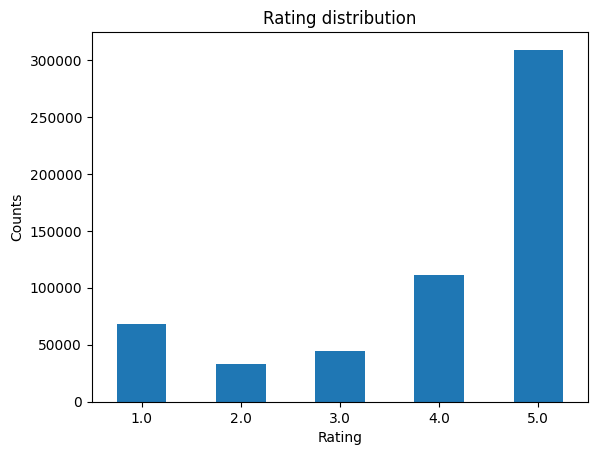

In [15]:
#Visualising the distribution using bargraph
df['Rating'].value_counts().sort_index().plot(kind='bar')
plt.xlabel('Rating')
plt.ylabel('Counts')
plt.xticks(rotation=0)
plt.title('Rating distribution')
plt.show()

In [16]:
#Dropping the Timestamp column
df = df.drop('Timestamp',axis=1)

We drop the **timestamp** because our clustering model focuses on **user-product interactions** and rating behavior rather than time of the rating behavior

In [17]:
#Checking for average rating
df['Rating'].mean()

np.float64(3.9863097811223547)

In [18]:
#checking rating distribution by percentage
df['Rating'].value_counts(normalize=True).sort_index()*100

,proportion
Rating,
1.0,12.068178
2.0,5.904844
3.0,7.860892
4.0,19.659994
5.0,54.506092


In [19]:
#Rating/Interaction each user has made
df['UserId'].value_counts().describe()

,count
count,453146.000000
mean,1.250712
std,1.229024
min,1.000000
25%,1.000000
50%,1.000000
75%,1.000000
max,330.000000


# **Checking sparsity**

In [20]:
total_possible = df['UserId'].nunique() * df['ProductId'].nunique()
actual_rating = len(df)

sparsity = 1 -(actual_rating / total_possible)
print("Sparsity: {:.2%}".format(sparsity))

Sparsity: 100.00%


In [21]:
print(sparsity)

0.9999635009866299


The data is highly sparse, which means most users have not rated most of the products.

# Insights of EDA



1. The dataset has total no. of 22,67,020 elements
2. The Dataset had 4 columns and 5,66,755 rows
3. Dropped the Timestamp column because our project focuses on user-product activity and rating beahvior not the time of rating behavior.
4. There are 4,53,146 **unique users** and 34,267 **unique products**
5. In the Rating distribution, 5.0 rating has more contribution(54%) whereas 2.0 has less contribution(5.89%).
6. 50% and 75% of the users have given 1 rating only
7. 1 user has minimum given 1 rating and 1 user has maximum given 424 rating.
8. After checking the sparsity, we got to know that the data is highly sparse means most of the users have not rated most of the products.


# Filtering Analysis

In [22]:
#Checking how many users have given more than 1 rating
(df['UserId'].value_counts()>1).sum()

np.int64(63461)

In [23]:
#Checking how many user have given more than 5 rating
(df['UserId'].value_counts()>5).sum()

np.int64(3258)

In [24]:
#Checking how many users have given more than 10 rating
(df['UserId'].value_counts()>10).sum()

np.int64(686)

In [25]:
#Checking how many products have atleast 5 rating
(df['ProductId'].value_counts()>5).sum()

np.int64(12236)

# Filtering

In [32]:
#Counting rating for each user and product
user_counts = df['UserId'].value_counts()
product_counts = df['ProductId'].value_counts()

#Filtering users and product together
df_filtered = df[
    df['UserId'].isin(user_counts[user_counts >= 5].index) &
    df['ProductId'].isin(product_counts[product_counts >= 5].index)
]

For the recommendation system, we selected 5 as the minimum interaction threshold for both users and products.

Reasons:

1. Users with very few ratings provide limited information about their preferences.
2. Products with very few ratings provide limited feedback for generating reliable recommendations.
3. A threshold of 5 provides a practical starting point between retaining sufficient data and removing low-interaction users and products.

We will apply iterative filtering to ensure that both users and products satisfy the minimum 5-interaction condition in the final dataset.

In [33]:
#Checking the filtered dataset
df_filtered.shape

(36360, 3)

In [34]:
#Printing unique users in filtered dataset
df_filtered['UserId'].nunique()

5238

In [35]:
#Printing unique products in filtered dataset
df_filtered['ProductId'].nunique()

9153

In [36]:
df_filtered['UserId'].value_counts().describe()

,count
count,5238.000000
mean,6.941581
std,6.797714
min,1.000000
25%,5.000000
50%,6.000000
75%,7.000000
max,288.000000


1. In the filtered dataset there are 5238 unique users.
2. Mean is 6.94 , so on an average each user has about 6 to 7rating.
3. 25% of users have 5 or fewer ratings
4. 50% of users have 6 ratings and 75% of users have 7 rating
5. max= 288 , meaning the most active user has given 368 ratings.



In [37]:
df_filtered['ProductId'].value_counts().describe()

,count
count,9153.000000
mean,3.972468
std,7.802013
min,1.000000
25%,1.000000
50%,2.000000
75%,4.000000
max,218.000000


1. There are 9,153 unique products in the fileterd datasets.
2. The mean is 3.97, so on an average ecah product has about 4 ratings.
3. 25% of products have 1 or fewer ratings
4. 50% of products have 2 or fewer ratings
5. 75% of products have 4 or fewer rating
6. The max is 218 meaning the most rated product has received 218 ratings.

Filtering again until the dataset stabilizes

In [38]:
df_filtered = df.copy()

In [39]:
while True:
  user_counts = df_filtered['UserId'].value_counts()
  product_counts = df_filtered['ProductId'].value_counts()

  new_df = df_filtered[
      df_filtered['UserId'].isin(user_counts[user_counts>=5].index) &
      df_filtered['ProductId'].isin(product_counts[product_counts >=5].index)
  ]

  if len(new_df) == len(df_filtered):
    break
  df_filtered = new_df

The above step will ensure that final dataset genuinely contains users and products with atleast 5 interactions within the final dataset

In [40]:
df_filtered.shape

(3951, 3)

In [41]:
df_filtered['UserId'].value_counts().describe()

,count
count,592.000000
mean,6.673986
std,3.540933
min,5.000000
25%,5.000000
50%,6.000000
75%,7.000000
max,53.000000


In [42]:
df_filtered['ProductId'].value_counts().describe()

,count
count,384.000000
mean,10.289062
std,10.265524
min,5.000000
25%,6.000000
50%,7.000000
75%,10.000000
max,102.000000


So, for the final dataset there are


* 3,951 interactions
* 592 unique users
* 384 unique products
* 50 % of users  has given 6 ratings
* user has given minimum rating of 5 and maximum of 53.


* The average is 10.28 ratings/product
* 50 % of products have 7 rating
*  A product has munimum of 5 rating and maximum of 102 rating



**So, now both sides satisfy the 5+ interaction threshold**

In [43]:
#shape of final dataset
df_filtered.shape

(3951, 3)

In [44]:
#No. of unique users
df_filtered['UserId'].nunique()

592

In [45]:
#No. of unique products
df_filtered['ProductId'].nunique()

384

# Feature Engineering

**User-Level Features**

In [46]:
#Average rating given by each user
  #This will tell how a user generally rates product

user_features = df_filtered.groupby('UserId')['Rating'].mean().reset_index()
user_features.head()


,UserId,Rating
0,A100UD67AHFODS,5.0
1,A100WO06OQR8BQ,4.0
2,A10HSMHBTT0GWI,5.0
3,A10I93B1FLOY8,3.8
4,A10MVOFKTZVNN4,4.5


In [47]:
#Renaming the average-rating column
user_features = user_features.rename(columns={'Rating': 'Avg_Rating'})
user_features.head()

,UserId,Avg_Rating
0,A100UD67AHFODS,5.0
1,A100WO06OQR8BQ,4.0
2,A10HSMHBTT0GWI,5.0
3,A10I93B1FLOY8,3.8
4,A10MVOFKTZVNN4,4.5


In [48]:
#Adding Rating count- how many rating each user has given
rating_count = df_filtered.groupby('UserId')['Rating'].count().reset_index()
rating_count = rating_count.rename(columns={'Rating': 'Rating_Count'})
rating_count.head()

,UserId,Rating_Count
0,A100UD67AHFODS,5
1,A100WO06OQR8BQ,5
2,A10HSMHBTT0GWI,5
3,A10I93B1FLOY8,5
4,A10MVOFKTZVNN4,8


In [49]:
#We will merge user_faetures and rating_count using UserID
user_features = user_features.merge(rating_count, on='UserId')
user_features.head()

,UserId,Avg_Rating,Rating_Count
0,A100UD67AHFODS,5.0,5
1,A100WO06OQR8BQ,4.0,5
2,A10HSMHBTT0GWI,5.0,5
3,A10I93B1FLOY8,3.8,5
4,A10MVOFKTZVNN4,4.5,8


In [50]:
#Rating Standard Deviation per user- how consistently a user rates products
rating_std = df_filtered.groupby('UserId')['Rating'].std().reset_index()

#Renaming the column
rating_std = rating_std.rename(columns={'Rating': 'Rating_Std'})
rating_std.head()

,UserId,Rating_Std
0,A100UD67AHFODS,0.000000
1,A100WO06OQR8BQ,1.732051
2,A10HSMHBTT0GWI,0.000000
3,A10I93B1FLOY8,1.643168
4,A10MVOFKTZVNN4,1.414214


**Rating Standard Deviation** tells how consistent a user is in giving ratings. A lower std deviation means user gives similar rating most of the time, while higher standard deviation means the user's ratings vary across the products.

In [51]:
#Merging the rating_std into user_features
user_features = user_features.merge(rating_std, on='UserId')
user_features.head()


,UserId,Avg_Rating,Rating_Count,Rating_Std
0,A100UD67AHFODS,5.0,5,0.000000
1,A100WO06OQR8BQ,4.0,5,1.732051
2,A10HSMHBTT0GWI,5.0,5,0.000000
3,A10I93B1FLOY8,3.8,5,1.643168
4,A10MVOFKTZVNN4,4.5,8,1.414214


In [52]:
#Summary of these three faetures
user_features.describe()

,Avg_Rating,Rating_Count,Rating_Std
count,592.000000,592.000000,592.000000
mean,4.424468,6.673986,0.746263
std,0.510007,3.540933,0.515597
min,1.600000,5.000000,0.000000
25%,4.166667,5.000000,0.447214
50%,4.555556,6.000000,0.666667
75%,4.800000,7.000000,1.115164
max,5.000000,53.000000,2.190890


**The summary statistics of the user-level features.**

The average rating is 4.28, the average rating count is about 7.18 and the average rating standard deviation os 0.85. These features capture the user's rating tendency, activity level and rating consistency which we can use for clustering.

** Important Observation**
**Rating_count** ranges from 5 to 143 while A**vg_Rating** ranges from 1 to 5 and **Rating_Std** from 0 to 2.19.

These features are on different scales , we will scale them before applying clustering algorithms

**Feature Scaling**

In [53]:
#Importing Standard Scaler
from sklearn.preprocessing import StandardScaler
sc=StandardScaler()

#Fit and transform the features
features_scaled = sc.fit_transform(
    user_features[['Avg_Rating','Rating_Count','Rating_Std']]
)

In [54]:
#Inspecting the scaled data
features_scaled[:5]

array([[ 1.1294322 , -0.47315275, -1.44860041],
       [-0.83298269, -0.47315275,  1.91355287],
       [ 1.1294322 , -0.47315275, -1.44860041],
       [-1.22546567, -0.47315275,  1.74101825],
       [ 0.14822475,  0.37479809,  1.29658625]])

In [55]:
#Inspecting the scaled data (easy to understand)
scaled_df = pd.DataFrame(
    features_scaled,
    columns=['Avg_Rating','Rating_Count','Rating_Std']
)
scaled_df.head()

,Avg_Rating,Rating_Count,Rating_Std
0,1.129432,-0.473153,-1.448600
1,-0.832983,-0.473153,1.913553
2,1.129432,-0.473153,-1.448600
3,-1.225466,-0.473153,1.741018
4,0.148225,0.374798,1.296586


**Clustering**

In [56]:
#Clustering using Elbow Method

#import K-Means
from sklearn.cluster import KMeans

In [57]:
#Calculating WCSS(Within-Cluster Sum of Squares) for different K values
wcss = []
for k in range(2,11):
  kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
  kmeans.fit(features_scaled)
  wcss.append(kmeans.inertia_)

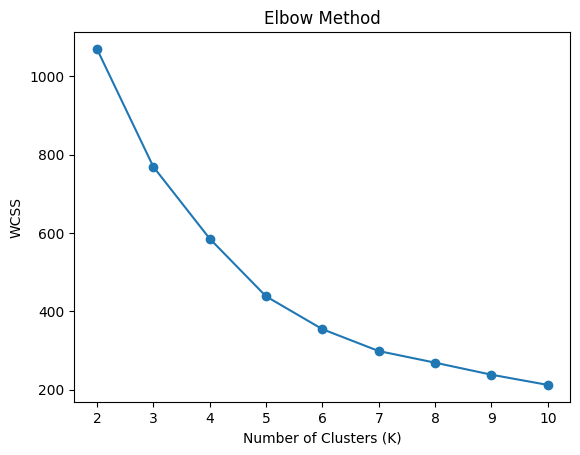

In [58]:
#Plot the Elbow Curve

plt.plot(range(2,11), wcss, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.title('Elbow Method')
plt.show()

In [59]:
for k, value in zip(range(2, 11), wcss):
    print(f"K = {k}, WCSS = {value:.2f}")

K = 2, WCSS = 1070.38
K = 3, WCSS = 769.52
K = 4, WCSS = 585.87
K = 5, WCSS = 438.51
K = 6, WCSS = 354.60
K = 7, WCSS = 298.72
K = 8, WCSS = 269.04
K = 9, WCSS = 238.32
K = 10, WCSS = 212.25


So, based on these WCSS values , K=5 is a reasonable elbow candidate

In [60]:
#Checking the Silhouette Score
from sklearn.metrics import silhouette_score

for k in range(2,11):
  kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
  labels = kmeans.fit_predict(features_scaled)

  score = silhouette_score(features_scaled, labels)
  print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 2, Silhouette Score = 0.4339
K = 3, Silhouette Score = 0.4475
K = 4, Silhouette Score = 0.3694
K = 5, Silhouette Score = 0.4046
K = 6, Silhouette Score = 0.4075
K = 7, Silhouette Score = 0.4064
K = 8, Silhouette Score = 0.3968
K = 9, Silhouette Score = 0.4132
K = 10, Silhouette Score = 0.3933


So, the highest silhouette score among the tested values is 0.4475 at K=3

Will evaluate the both K=3 and K=5 clusters and compare resulting cluster characteristics

In [61]:
#K-Means with K=3
kmeans_3 = KMeans(n_clusters=3, random_state=42, n_init=10)
cluster_labels_3 = kmeans_3.fit_predict(features_scaled)

In [62]:
#Adding the cluster label to user feature table
user_features['Cluster_3'] = cluster_labels_3

In [63]:
#Checking how many users are present in each cluster
user_features['Cluster_3'].value_counts().sort_index()

,count
Cluster_3,
0,343
1,244
2,5


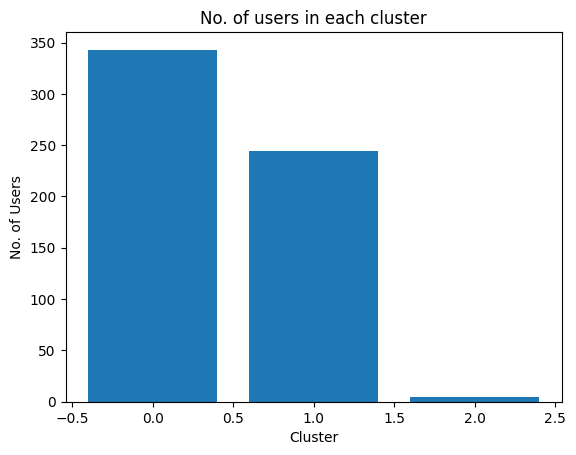

In [64]:
#Visualizing no. of user present in each cluster

cluster_counts = user_features['Cluster_3'].value_counts().sort_index()

plt.bar(cluster_counts.index, cluster_counts.values)
plt.xlabel('Cluster')
plt.ylabel('No. of Users')
plt.title('No. of users in each cluster')
plt.show()

In [65]:
#Calculating cluster wise averages
cluster_summary = user_features.groupby('Cluster_3')[
    ['Avg_Rating','Rating_Count','Rating_Std']
].mean()

cluster_summary

,Avg_Rating,Rating_Count,Rating_Std
Cluster_3,,,
0,4.749213,6.422741,0.399664
1,3.974865,6.463115,1.227494
2,4.087631,34.200000,1.038863


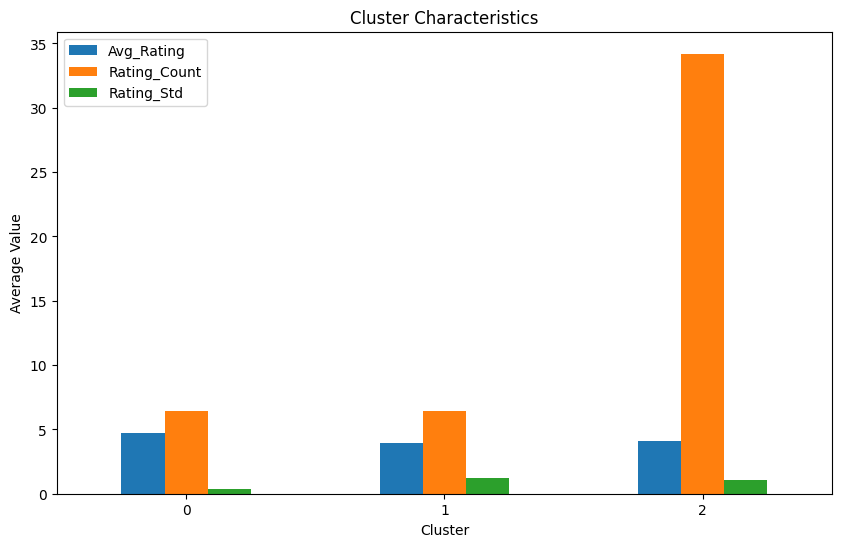

In [66]:
#Visualizing the cluster-wise averages
cluster_summary.plot(kind='bar', figsize=(10,6))

plt.xlabel('Cluster')
plt.ylabel('Average Value')
plt.title('Cluster Characteristics')
plt.xticks(rotation=0)
plt.legend()
plt.show()

**Cluster 0: **

Users who give lower average ratings, have relatively few ratings and show more variation in their ratings.

**Cluster 1: **

Users who give high ratings, have relatively few ratings and are quite consistent in their ratings.

**CLuster 2: **

Users who give high ratings are much more active because they have average of about 22 ratings.

In [67]:
#Evaluating K-Means Clustering using davies_bouldin_score
from sklearn.metrics import davies_bouldin_score

#Calculating the score
db_score = davies_bouldin_score(features_scaled, cluster_labels_3)
print("Davies-Bouldin Index",db_score)

Davies-Bouldin Index 0.7925146713963818


In [68]:
#K-Means with K=5
kmeans_5 = KMeans(n_clusters=5, random_state=42, n_init=10)
cluster_labels_5 = kmeans_5.fit_predict(features_scaled)

In [69]:
user_features['Cluster_5']=cluster_labels_5
user_features['Cluster_5'].value_counts().sort_index()

,count
Cluster_5,
0,87
1,258
2,38
3,2
4,207


In [70]:
#Cluster = 5 summary
cluster_summary_5 = user_features.groupby('Cluster_5')[
    ['Avg_Rating','Rating_Count','Rating_Std']
].mean()

cluster_summary_5

,Avg_Rating,Rating_Count,Rating_Std
Cluster_5,,,
0,3.563542,5.885057,1.548663
1,4.824440,6.000000,0.297642
2,4.382081,13.710526,0.832802
3,4.109473,50.500000,1.105169
4,4.298616,6.130435,0.948818


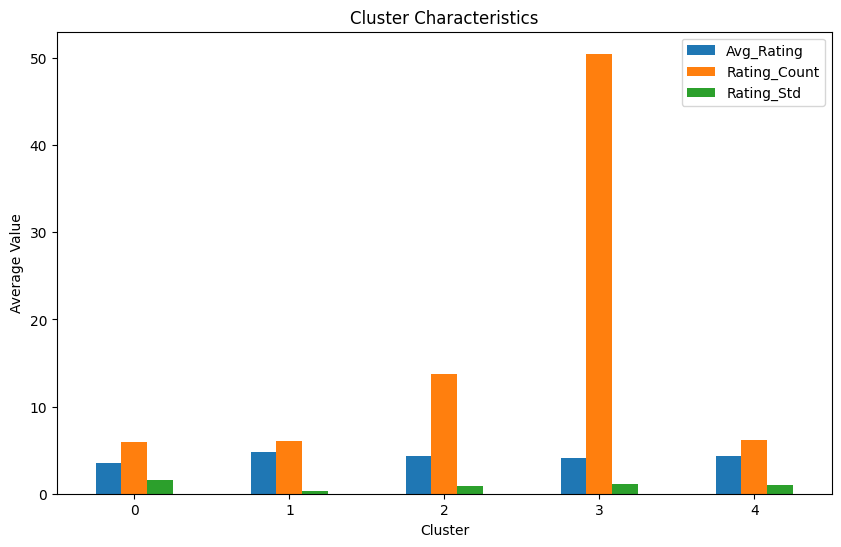

In [71]:
#Visualising the cluster_summary_5
cluster_summary_5.plot(kind='bar',figsize=(10,6))

plt.xlabel('Cluster')
plt.ylabel('Average Value')
plt.title('Cluster Characteristics')
plt.xticks(rotation=0)
plt.legend()
plt.show()

In [72]:
#Calculating silhouette score of K=5
silhouette_5 = silhouette_score(features_scaled, cluster_labels_5)
print("Silhouette Score",silhouette_5)

Silhouette Score 0.40456770654721136


In [73]:
#Calculating Davies-Bouldin Index for K=5
db_score_5 = davies_bouldin_score(features_scaled, cluster_labels_5)
print("Davies-Bouldin Index:",db_score_5)

Davies-Bouldin Index: 0.7690771014848019


*  K=3 has a higher silhouette score means the clusters are better separated.
* K=5 has a slightly lower davies-Bouldin index , according to this metric, K=5 has slightly better separation.
* but K=5 creates a very small cluster of 2 users, which makes the segmentation less balanced.

So, based on the overall combination of metrics and cluster sizes, K=3 gives us more balanced clustering structure, while K=5 provides more detailed segementation but creates an extremely small cluster

In [74]:
#Comparison graph of K=3 and K=5
comparison = pd.DataFrame({
    'K':['K=3','K=5'],
    'Silhouette Score': [0.4695, 0.3962],
    'Davies-Bouldin Index':[0.7762, 0.8457]
})
comparison

,K,Silhouette Score,Davies-Bouldin Index
0,K=3,0.4695,0.7762
1,K=5,0.3962,0.8457


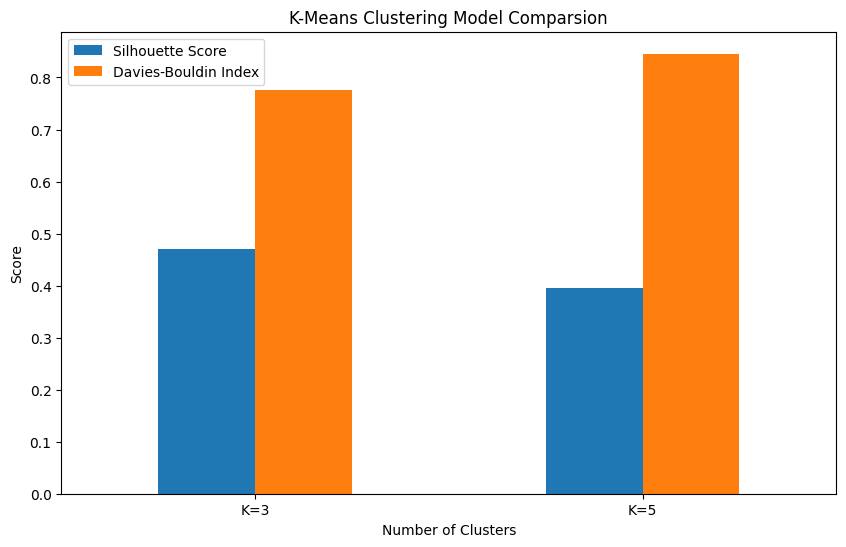

In [75]:
#Graph
comparison.set_index('K').plot(
    kind='bar',
    figsize=(10,6)
)

plt.xlabel('Number of Clusters')
plt.ylabel('Score')
plt.title('K-Means Clustering Model Comparsion')
plt.xticks(rotation=0)
plt.legend()
plt.show()

Compared the K=3 and K=5 using silhouette score and davies-bouldin index.

K=3 achieved a higher silhouette score, while K=5 had a slightly higher Davies-Bouldin Index.

However, K=5 produced a very small cluster containing only two users.

Considering the overall clustering structure and balanced segementation, Will select K=3 for final recoemmendation system

In [76]:
#Creating PCA Co-ordinates
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
features_pca = pca.fit_transform(features_scaled)

features_pca.shape

(592, 2)

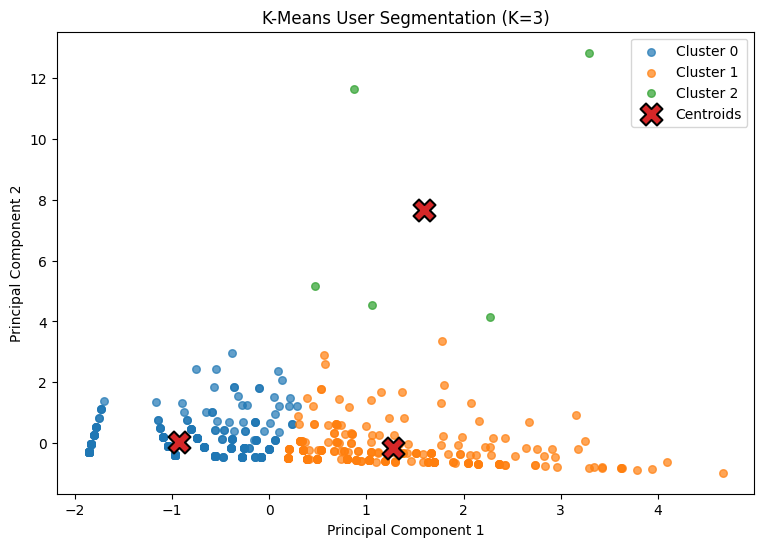

In [77]:
#scatter plot for K=3
plt.figure(figsize=(9, 6))

for cluster in sorted(set(cluster_labels_3)):
    plt.scatter(
        features_pca[cluster_labels_3 == cluster, 0],
        features_pca[cluster_labels_3 == cluster, 1],
        s=30,
        alpha=0.7,
        label=f'Cluster {cluster}'
    )

# Convert K-Means centroids to PCA coordinates
centroids_pca = pca.transform(kmeans_3.cluster_centers_)

# Plot centroids
plt.scatter(
    centroids_pca[:, 0],
    centroids_pca[:, 1],
    marker='X',
    s=250,
    edgecolor='black',
    linewidth=1.5,
    label='Centroids'
)

plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.title('K-Means User Segmentation (K=3)')
plt.legend()
plt.show()

In [78]:
#Final Cluster summary
cluster_summary = user_features.groupby('Cluster_3')[
    ['Avg_Rating', 'Rating_Count', 'Rating_Std']
].mean()

cluster_summary

,Avg_Rating,Rating_Count,Rating_Std
Cluster_3,,,
0,4.749213,6.422741,0.399664
1,3.974865,6.463115,1.227494
2,4.087631,34.200000,1.038863


Based on the cluster summary,


*   Cluster 0 represents users with relatively lower and more varied ratings
* Cluster 1 represents users who give high and consistent ratings
* Cluster 2 represents highly active users who provide a larger number of ratings.



# Recommendation Sysytem Part

In [79]:
#Connect users with their clusters
df_recommend =df_filtered.merge (
    user_features[['UserId','Cluster_3']],
    on='UserId'
)
df_recommend.head()

,UserId,ProductId,Rating,Cluster_3
0,A1T1YSCDW0PD25,B00000DM9W,5.0,0
1,A25SDTIJI2EFPG,B00000DM9W,5.0,1
2,A1N3IS6ZQE7Y8L,B00000DM9W,5.0,0
3,A11ED8O95W2103,B00000DM9W,5.0,1
4,A3NCIN6TNL0MGA,B00000DM9W,5.0,0


In [80]:
#Find the average rating for each product within each cluster
cluster_product_rating = df_recommend.groupby(
    ['Cluster_3','ProductId']
)['Rating'].mean().reset_index()

cluster_product_rating.head()

,Cluster_3,ProductId,Rating
0,0,B00000DM9W,5.0
1,0,B00000J061,5.0
2,0,B00000J1TX,5.0
3,0,B00000J1V5,5.0
4,0,B00000J3Q1,4.5


In [81]:
#Checking how many users rated each product
cluster_product_count = df_recommend.groupby(
    ['Cluster_3','ProductId']
)['Rating'].count().reset_index()

cluster_product_count = cluster_product_count.rename(
    columns={'Rating':'Rating_Count'}
)
cluster_product_count.head()

,Cluster_3,ProductId,Rating_Count
0,0,B00000DM9W,3
1,0,B00000J061,6
2,0,B00000J1TX,4
3,0,B00000J1V5,6
4,0,B00000J3Q1,4


In [82]:
#Combine average rating and rating count
cluster_product_summary = cluster_product_rating.merge(
    cluster_product_count,
    on=['Cluster_3','ProductId']
)
cluster_product_summary.head()

,Cluster_3,ProductId,Rating,Rating_Count
0,0,B00000DM9W,5.0,3
1,0,B00000J061,5.0,6
2,0,B00000J1TX,5.0,4
3,0,B00000J1V5,5.0,6
4,0,B00000J3Q1,4.5,4


In [83]:
#Checking the rating count distribution
cluster_product_summary['Rating_Count'].describe()

,Rating_Count
count,893.000000
mean,4.424412
std,5.424796
min,1.000000
25%,2.000000
50%,3.000000
75%,5.000000
max,65.000000




*   Mean :4.42 ratings per product within a cluster
* Median: 3 ratings, 50% product have 3 ratings or fewer
* 75% of products have 5 ratings
* A product has minimum of 1 rating and maximum of 65 rating




**Will keep products with atleast 3 ratings within the cluster**

In [84]:
cluster_product_summary_filtered = cluster_product_summary[
    cluster_product_summary['Rating_Count']>=3
]
cluster_product_summary_filtered.head()

,Cluster_3,ProductId,Rating,Rating_Count
0,0,B00000DM9W,5.0,3
1,0,B00000J061,5.0,6
2,0,B00000J1TX,5.0,4
3,0,B00000J1V5,5.0,6
4,0,B00000J3Q1,4.5,4


In [85]:
#Sorting products within each cluster
cluster_product_ranked = cluster_product_summary_filtered.sort_values(
    ['Cluster_3','Rating','Rating_Count'],
    ascending=[True,False,False]
)
cluster_product_ranked.head(10)

,Cluster_3,ProductId,Rating,Rating_Count
45,0,B00004YZQ8,5.0,10
348,0,B0002XQJFA,5.0,10
162,0,B00007KDVK,5.0,9
219,0,B00009R6WY,5.0,8
271,0,B0000CD0B7,5.0,8
191,0,B00009EHJV,5.0,7
278,0,B0000X0VCY,5.0,7
354,0,B0002YE686,5.0,7
1,0,B00000J061,5.0,6
3,0,B00000J1V5,5.0,6


In [86]:
#To get Top 5 products for each cluster
top_products = cluster_product_ranked.groupby('Cluster_3').head(5)
top_products = top_products.reset_index(drop=True)
top_products

,Cluster_3,ProductId,Rating,Rating_Count
0,0,B00004YZQ8,5.000000,10
1,0,B0002XQJFA,5.000000,10
2,0,B00007KDVK,5.000000,9
3,0,B00009R6WY,5.000000,8
4,0,B0000CD0B7,5.000000,8
5,1,B000053HC5,5.000000,6
6,1,B00009MDBQ,5.000000,6
7,1,B00008OE6I,5.000000,5
8,1,B00008OT2G,5.000000,5
9,1,B0000BZL5A,5.000000,5


In [87]:
#Create a recommendation function
def recommend_products(user_id, top_n=5):
  cluster = user_features.loc[
      user_features['UserId'] == user_id, 'Cluster_3'
  ].values[0]

  rated_products = df_recommend[
      df_recommend['UserId'] == user_id
  ]['ProductId'].tolist()

  recommendations = top_products[
      (top_products['Cluster_3'] == cluster) &
      (~top_products['ProductId'].isin(rated_products))
  ].head(top_n)

  return recommendations[['ProductId','Rating','Rating_Count']]

In [88]:
#Testing the function
test_user = user_features['UserId'].iloc[0]
print("User ID: ",test_user)
print("Recommended Products:")
recommend_products(test_user)

User ID:  A100UD67AHFODS
Recommended Products:


,ProductId,Rating,Rating_Count
0,B00004YZQ8,5.0,10
1,B0002XQJFA,5.0,10
2,B00007KDVK,5.0,9
3,B00009R6WY,5.0,8
4,B0000CD0B7,5.0,8


In [89]:
#Checking if the recommended products have already rated by the user
df_recommend[
    (df_recommend['UserId']==test_user) &
    (df_recommend['ProductId'].isin(top_products['ProductId']))
]

,UserId,ProductId,Rating,Cluster_3


So, for the user ,the Top 5 products we selected are all unseen products

**Checking Recommendation Coverage**

In [90]:
#How many users actually recieve recommendations after filtering
rated_count = df_recommend.groupby('UserId')['ProductId'].count()
print("Total users:",len(user_features))
print("Users with ratings:",len(rated_count))

Total users: 592
Users with ratings: 592


so, every user in user_features has ratings.

In [91]:
#Checking users selected for the evaluation using 100 samples
sample_users = user_features['UserId'].sample(100, random_state=42)
print("Users selected for evaluation:", len(sample_users))

Users selected for evaluation: 100


In [92]:
#Checking how many of them receive recommendations
recommendation_count = []
for user_id in sample_users:
  recommendations = recommend_products(user_id, top_n=5)
  recommendation_count.append(len(recommendations))

print("Users receiving recommendations: ", sum(count > 0 for count in recommendation_count))
print("Users with no recommendations:",sum(count == 0 for count in recommendation_count))

Users receiving recommendations:  98
Users with no recommendations: 2


So, the recommendation logic is able to generate recommendations for every user

In [93]:
#Checking users with already rated recommendations using 100 samples
already_rated_count = 0

for user_id in sample_users:
  recommendations = recommend_products(user_id, top_n=5)

  rated_products = set(
      df_recommend[df_recommend['UserId'] == user_id]['ProductId']
  )
  if any (product in rated_products for product in recommendations['ProductId']):
    already_rated_count += 1
print("Users with already-rated recommendations: ", already_rated_count)

Users with already-rated recommendations:  0


In [94]:
#Checking average rating of the recommendation
recommended_ratings = []
for user_id in sample_users:
  recommendations = recommend_products(user_id, top_n=5)
  recommended_ratings.extend(recommendations['Rating'].tolist())
print("Average recommend rating: ", sum(recommended_ratings)/len(recommended_ratings))

Average recommend rating:  5.0


So, for a sample of 100 users, the system provided recommendations to all users with no already-rated products included. The recommended products had an average cluster rating of 5.0

# Insights for model building and evaluation

* Most users in the filtered data do not rate a large number of products , user-activity wa low.
* Users showed different rating behaviors, which allowed to form 3 meaningful froups.
* One group tends to give lower and more varied rating.
* Another group gives high and consistent ratings, meaning they generally like the products they rate.
* The third group is more active , giving conisderavly more ratings than the other two groups.
* Some products are highly rated within specific user groups, rather than being equally popular across all groups.

* Products with more ratings within a cluster give us more confidence that their high rating is not based on very few users.
* The top recommended products mostly had very high average ratings, with 5.0 being common among the selected products.
* The recommendation system was able to provide recommendations to all 100 users tested.
* The recommendations were new to the users in the test sample, since none of them had already rated the recommended products.

In [95]:
#Save the trained model
import joblib
joblib.dump(kmeans_3, 'kmeans_model.pkl')

['kmeans_model.pkl']

In [97]:
#Save the scaler
joblib.dump(sc, 'scaler.pkl')

['scaler.pkl']

In [98]:
#Verifying saved files
import os
print(os.listdir())

['.config', 'kmeans_model.pkl', 'scaler.pkl', 'ratings.csv', 'sample_data']


In [100]:
joblib.dump(user_features,'user_features.pkl')
joblib.dump(df_recommend,'df_recommend.pkl')
joblib.dump(top_products,'top_products.pkl')

['top_products.pkl']

In [101]:
files.download('user_features.pkl')
files.download('df_recommend.pkl')
files.download('top_products.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [99]:
#Downloading both the files
from google.colab import files
files.download('kmeans_model.pkl')
files.download('scaler.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>